<a href="https://colab.research.google.com/github/jkirkpa6-az/Capstone_Project/blob/main/ATowne_Methodology_pt1_CatBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DAT 490 Methodology Part 1
## Autumn Towne

### **Step 0: Importing libraries and dataset**

In [1]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 23.4 MB/s eta 0:00:00


In [2]:
pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 15.5 MB/s eta 0:00:00


In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scipy.stats as stats
import warnings
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
nsduh_2021_2024 = pd.read_csv('/content/drive/MyDrive/nsduh_2021_2024.csv')

/tmp/ipykernel_2564/2466007834.py:1: DtypeWarning: Columns (2281) have mixed types. Specify dtype option on import or set low_memory=False.
  nsduh_2021_2024 = pd.read_csv('/content/drive/MyDrive/nsduh_2021_2024.csv')


### **Step 1: Initial variable selection**
The response variable I investigate is MRJFLAG: if the respondent ever used marijuana.
The predictor variables I chose are "GRSKMRJMON", "GRSKMRJWK", and "DIFGETMRJ".

The first two variables are related to risk. Respondents were asked "How much do people risk harming themselves physically and in other ways when they smoke marijuana once a month?", and could select "No risk", "Slight risk", "Moderate risk", or "Great Risk".

GRSKMRJMON is that question recoded as binary with 1 being the respondent selected "Great Risk". GRSKMRJWK is the same except the question was "once or twice a week" rather than "once a month".

DIFGETMRJ was the question "How difficult or easy would it be for you to get some marijuana, if you wanted some?" Options were "Probably impossible", "Very difficult", "Fairly difficult", "Fairly easy", or "Very Easy".

In [61]:
X = nsduh_2021_2024[["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ"]].astype(str)
y = nsduh_2021_2024["MRJFLAG"]

### **Step 2: Train/test split, model selection, and hyperparameter adjustments**

I used the default train and test size split: 75% training and 25% testing. I used 500 iterations because that is a typical maximum number of trees for a model like this. CatBoostClassifier's default learning rate is selected automatically for binary classification, so I did not change it. I left the depth at its default of 6.

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y)

model = CatBoostClassifier(iterations = 500)

model.fit(X_train, y_train,
          cat_features=["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ"])

Learning rate set to 0.176216
0:	learn: 0.6369468	total: 41.3ms	remaining: 20.6s
1:	learn: 0.6004553	total: 71.7ms	remaining: 17.8s
2:	learn: 0.5772710	total: 111ms	remaining: 18.3s
3:	learn: 0.5630780	total: 145ms	remaining: 18s
4:	learn: 0.5534474	total: 173ms	remaining: 17.2s
5:	learn: 0.5471845	total: 208ms	remaining: 17.2s
6:	learn: 0.5427101	total: 239ms	remaining: 16.8s
7:	learn: 0.5397973	total: 266ms	remaining: 16.3s
8:	learn: 0.5376924	total: 294ms	remaining: 16.1s
9:	learn: 0.5362775	total: 319ms	remaining: 15.6s
10:	learn: 0.5354614	total: 349ms	remaining: 15.5s
11:	learn: 0.5348033	total: 378ms	remaining: 15.4s
12:	learn: 0.5343981	total: 404ms	remaining: 15.1s
13:	learn: 0.5340443	total: 432ms	remaining: 15s
14:	learn: 0.5338749	total: 454ms	remaining: 14.7s
15:	learn: 0.5337282	total: 483ms	remaining: 14.6s
16:	learn: 0.5336132	total: 510ms	remaining: 14.5s
17:	learn: 0.5335178	total: 533ms	remaining: 14.3s
18:	learn: 0.5334296	total: 563ms	remaining: 14.2s
19:	learn: 0.

CatBoostClassifier(iterations=500)

### **Step 3: Model evaluation**
I calculated the accuracy and F1 score of the model and displayed a confusion matrix. I will later calculate feature importance.

In [63]:
print("Test accuracy:", model.score(X_test, y_test))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.7289153516545921
Binary F1 Score: 0.7256


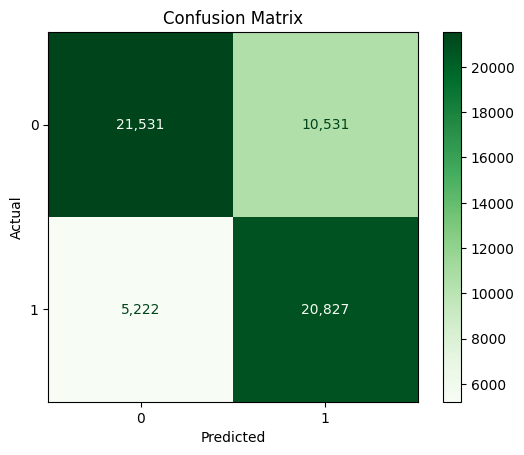

In [64]:
# Get predictions from the trained model
y_pred = model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Greens, values_format=',d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## **Step 4: Adding variables and repeating Steps 1-3**

This time, I let the iterations be set to the default number (1000).

I added the variable "COUTYP4": the metro status of the respondent's county, with 1 for Large Metro, 2 for Small Metro, and 3 for Nonmetro.


In [66]:
X = nsduh_2021_2024[
    ["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4"]].astype(str)
y = nsduh_2021_2024["MRJFLAG"]

X_train, X_test, y_train, y_test = train_test_split(X, y)

model = CatBoostClassifier()

model.fit(X_train, y_train,
          cat_features=["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4"])

Learning rate set to 0.093325
0:	learn: 0.6611202	total: 37.9ms	remaining: 37.9s
1:	learn: 0.6357817	total: 72.4ms	remaining: 36.1s
2:	learn: 0.6157522	total: 106ms	remaining: 35.2s
3:	learn: 0.5994561	total: 134ms	remaining: 33.3s
4:	learn: 0.5879030	total: 156ms	remaining: 31s
5:	learn: 0.5774903	total: 185ms	remaining: 30.6s
6:	learn: 0.5692604	total: 215ms	remaining: 30.5s
7:	learn: 0.5628054	total: 244ms	remaining: 30.3s
8:	learn: 0.5574459	total: 274ms	remaining: 30.1s
9:	learn: 0.5532408	total: 303ms	remaining: 30s
10:	learn: 0.5495470	total: 335ms	remaining: 30.1s
11:	learn: 0.5466141	total: 368ms	remaining: 30.3s
12:	learn: 0.5441034	total: 402ms	remaining: 30.5s
13:	learn: 0.5422044	total: 445ms	remaining: 31.3s
14:	learn: 0.5405329	total: 475ms	remaining: 31.2s
15:	learn: 0.5392409	total: 504ms	remaining: 31s
16:	learn: 0.5382229	total: 531ms	remaining: 30.7s
17:	learn: 0.5373842	total: 560ms	remaining: 30.5s
18:	learn: 0.5365905	total: 588ms	remaining: 30.4s
19:	learn: 0.53

CatBoostClassifier()

Test accuracy: 0.7280721378052348
Binary F1 Score: 0.7247


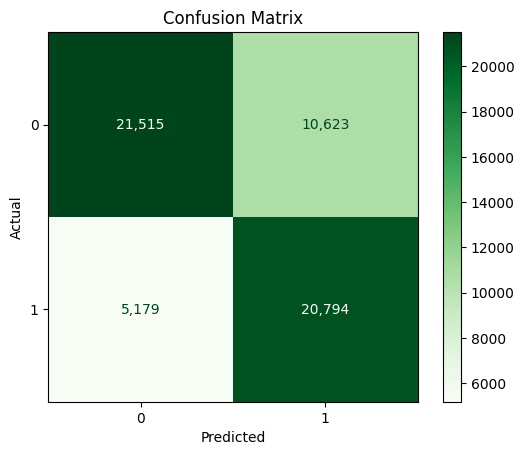

In [67]:
print("Test accuracy:", model.score(X_test, y_test))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

# Get predictions from the trained model
y_pred = model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Greens, values_format=',d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Metro status did not significantly improve the model.**

I then added the following variables related to availability, attitude, and religion:

* APPDRGMON2 is if someone has approached them trying to sell drugs in the past month.

* SNFAMJEV is "How do you feel about adults trying marijuana or any cannabis product once or twice?"

* SNRLGSVC is "During the past 12 months, how many times did you attend religious services excluding special occasions such as weddings or funerals?"

* SNYSELL is "During the past 12 months, how many times have you sold illegal drugs?"

* SNRLGIMP: Are your religious beliefs a very important part of your life?

* SNRLDCSN Do your religious beliefs influence how you make decisions in your life?

In [71]:
nsduh_2021_2024['SNFAMJEV'] = nsduh_2021_2024['SNFAMJEV'].where(
    nsduh_2021_2024['SNFAMJEV'].isin([1, 2, 3]), np.nan)

nsduh_2021_2024['SNRLGSVC'] = nsduh_2021_2024['SNRLGSVC'].where(
    nsduh_2021_2024['SNRLGSVC'].isin([1, 2, 3, 4, 5, 6]), np.nan)

nsduh_2021_2024['SNYSELL'] = nsduh_2021_2024['SNYSELL'].where(
    nsduh_2021_2024['SNYSELL'].isin([1, 2, 3, 4, 5]), np.nan)

nsduh_2021_2024['SNRLGIMP'] = nsduh_2021_2024['SNRLGIMP'].where(
    nsduh_2021_2024['SNRLGIMP'].isin([1, 2, 3, 4]), np.nan)

nsduh_2021_2024['SNRLDCSN'] = nsduh_2021_2024['SNRLDCSN'].where(
    nsduh_2021_2024['SNRLDCSN'].isin([1, 2, 3, 4]), np.nan)

In [72]:
X = nsduh_2021_2024[
    ["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4", "APPDRGMON2",
     "SNFAMJEV", "SNRLGSVC", "SNYSELL", "SNRLGIMP", "SNRLDCSN"]].astype(str)
y = nsduh_2021_2024["MRJFLAG"]

X_train, X_test, y_train, y_test = train_test_split(X, y)

model = CatBoostClassifier()

model.fit(X_train, y_train,
          cat_features=["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4",
                        "APPDRGMON2", "SNFAMJEV", "SNRLGSVC", "SNYSELL",
                        "SNRLGIMP", "SNRLDCSN"])

Learning rate set to 0.093325
0:	learn: 0.6562898	total: 80.8ms	remaining: 1m 20s
1:	learn: 0.6278676	total: 150ms	remaining: 1m 14s
2:	learn: 0.6042354	total: 199ms	remaining: 1m 6s
3:	learn: 0.5858575	total: 243ms	remaining: 1m
4:	learn: 0.5692723	total: 311ms	remaining: 1m 1s
5:	learn: 0.5563248	total: 359ms	remaining: 59.5s
6:	learn: 0.5452371	total: 405ms	remaining: 57.5s
7:	learn: 0.5372498	total: 454ms	remaining: 56.3s
8:	learn: 0.5302588	total: 508ms	remaining: 56s
9:	learn: 0.5247404	total: 558ms	remaining: 55.2s
10:	learn: 0.5197954	total: 615ms	remaining: 55.3s
11:	learn: 0.5161789	total: 679ms	remaining: 55.9s
12:	learn: 0.5131540	total: 757ms	remaining: 57.5s
13:	learn: 0.5102003	total: 806ms	remaining: 56.7s
14:	learn: 0.5080237	total: 853ms	remaining: 56s
15:	learn: 0.5060058	total: 904ms	remaining: 55.6s
16:	learn: 0.5043338	total: 966ms	remaining: 55.9s
17:	learn: 0.5029928	total: 1.02s	remaining: 55.6s
18:	learn: 0.5017806	total: 1.07s	remaining: 55.4s
19:	learn: 0.50

CatBoostClassifier()

Test accuracy: 0.7603379738775791
Binary F1 Score: 0.7436


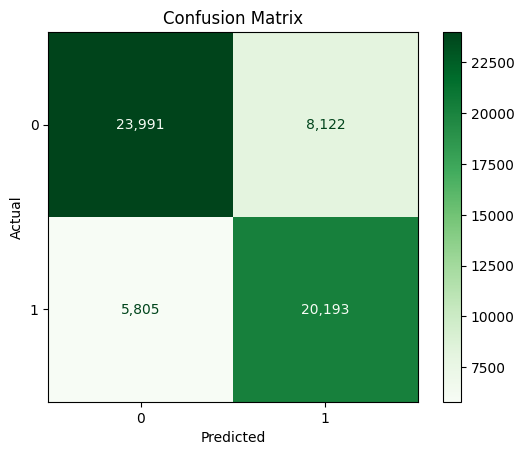

In [73]:
print("Test accuracy:", model.score(X_test, y_test))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

# Get predictions from the trained model
y_pred = model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Greens, values_format=',d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Availability, attitude, and religion variables improved the model.**

Lastly, I added mental health variables:

* IRAMDELT lifetime major depressive episode.

* IRAMDEIMP major depressive episode with severe role impairment.

* SMIPY Serious Mental Illness (SMI) indicator for respondents based on the 2012 predicted probability of SMI if it is greater than or equal to a specified cutoff point (0.260573529) then SMIPY=1, and if SMIPPPY is less than the cutoff point then SMIPY=0.

* AMIPY is an indicator for Any Mental Illness (AMI) its cutoff point is 0.0192519810.

* AMISUD5ANYO is if the respondent had an AMI, Substance Use Disorder, both, or neither within the past year.

I increased the size of the training set to be 80% because the data is complex. I also increased the depth from 6 to 10.

In [74]:
X = nsduh_2021_2024[
    ["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4", "APPDRGMON2",
     "SNFAMJEV", "SNRLGSVC", "SNYSELL", "SNRLGIMP", "SNRLDCSN", "IRAMDELT",
     "IRAMDEIMP", "SMIPY", "AMIPY", "AMISUD5ANYO"]].astype(str)
y = nsduh_2021_2024["MRJFLAG"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.8)

model = CatBoostClassifier(depth = 10)

model.fit(X_train, y_train,
          cat_features=["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4",
                        "APPDRGMON2", "SNFAMJEV", "SNRLGSVC", "SNYSELL",
                        "SNRLGIMP", "SNRLDCSN", "IRAMDELT", "IRAMDEIMP",
                        "SMIPY", "AMIPY", "AMISUD5ANYO"])

Learning rate set to 0.095933
0:	learn: 0.6448215	total: 210ms	remaining: 3m 29s
1:	learn: 0.6080951	total: 394ms	remaining: 3m 16s
2:	learn: 0.5773040	total: 643ms	remaining: 3m 33s
3:	learn: 0.5539615	total: 858ms	remaining: 3m 33s
4:	learn: 0.5360788	total: 1.07s	remaining: 3m 33s
5:	learn: 0.5227863	total: 1.26s	remaining: 3m 29s
6:	learn: 0.5119471	total: 1.47s	remaining: 3m 28s
7:	learn: 0.5031348	total: 1.69s	remaining: 3m 29s
8:	learn: 0.4962903	total: 1.91s	remaining: 3m 30s
9:	learn: 0.4908747	total: 2.19s	remaining: 3m 37s
10:	learn: 0.4859667	total: 2.46s	remaining: 3m 40s
11:	learn: 0.4820856	total: 2.73s	remaining: 3m 45s
12:	learn: 0.4789860	total: 3.01s	remaining: 3m 48s
13:	learn: 0.4762163	total: 3.29s	remaining: 3m 51s
14:	learn: 0.4739405	total: 3.54s	remaining: 3m 52s
15:	learn: 0.4720680	total: 3.81s	remaining: 3m 54s
16:	learn: 0.4704210	total: 4.13s	remaining: 3m 58s
17:	learn: 0.4690188	total: 4.41s	remaining: 4m
18:	learn: 0.4678242	total: 4.67s	remaining: 4m


CatBoostClassifier(depth=10)

Test accuracy: 0.770397298285616
Binary F1 Score: 0.7457


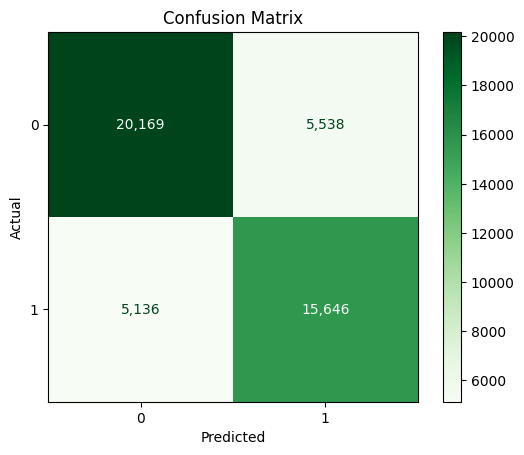

In [75]:
print("Test accuracy:", model.score(X_test, y_test))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

# Get predictions from the trained model
y_pred = model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Greens, values_format=',d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Adding mental health variables added only a marginal improvement to the model's predictive strength.**

Going forward, I will explore different outcome variables: particularly marijuana use within the past month and cocaine use, respectively.

I will also discuss findings with my teammates and combine significant predictor variables into a model.

Lastly, we may design models that predict multiple outcomes: marijuana use or cocaine use or alcohol use rather than binary yes/no.